In [1]:
install.packages("tidyverse")
install.packages("pwt10")
install.packages("stargazer")
install.packages("RSQLite")
install.packages("DBI")
install.packages("janitor")
install.packages("tibble")
install.packages("dplyr")
install.packages("corrplot")

library(tidyverse)
library(pwt10)
library(stargazer)
library(RSQLite)
library(DBI)
library(janitor)
library(tibble)
library(dplyr)
library(corrplot)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘snakecase’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubri

In [2]:
data("pwt10.01")
pwt_cols <- sort(colnames(pwt10.01))
pwt_cols <- as.data.frame(pwt_cols)
print(head(pwt_cols))
cat("\n")
pwt <- pwt10.01 %>%
  select(country,isocode,year,hc,rgdpe,emp,csh_i,pop,delta,rwtfpna,rtfpna) %>%
  mutate(per_capita = rgdpe/pop,n=pop) %>%
  drop_na() %>%
  filter(isocode == "ZMB")
print(head(pwt))

  pwt_cols
1      avh
2     ccon
3      cda
4    cgdpe
5    cgdpo
6       ck

         country isocode year       hc     rgdpe      emp      csh_i      pop
ZMB-1959  Zambia     ZMB 1959 1.270499  8605.633 1.016879 0.05228807 3.118859
ZMB-1960  Zambia     ZMB 1960 1.277846  9143.686 1.040616 0.05320368 3.198477
ZMB-1961  Zambia     ZMB 1961 1.289174  8899.026 1.063718 0.04730785 3.280061
ZMB-1962  Zambia     ZMB 1962 1.300603  8682.625 1.086967 0.04271275 3.362628
ZMB-1963  Zambia     ZMB 1963 1.312133  9177.950 1.110992 0.03162815 3.448143
ZMB-1964  Zambia     ZMB 1964 1.323765 10725.598 1.136101 0.02066904 3.537590
              delta   rwtfpna    rtfpna per_capita        n
ZMB-1959 0.03362352 0.5952920 0.6045370   2759.224 3.118859
ZMB-1960 0.03263622 0.5957134 0.6116154   2858.762 3.198477
ZMB-1961 0.03180699 0.5898252 0.6091271   2713.068 3.280061
ZMB-1962 0.03106741 0.5907698 0.5994263   2582.095 3.362628
ZMB-1963 0.03035675 0.5988609 0.6118268   2661.708 3.448143
ZMB-1964 0.02986

In [12]:
countries <- c("Zambia","Aruba")
pwt2 <- pwt10.01 %>% select(country,emp) %>%
                     filter(country %in% countries) %>%
                     mutate(Aruba_count = ifelse(country == "Aruba",1,0)) %>%
                     drop_na()
mean_1 <- pwt2 %>%
  filter(Aruba_count==1) %>%
  summarise(aruba_mean = mean(emp))
mean_2 <- pwt2 %>%
  filter(Aruba_count==0) %>%
  summarise(zambia_mean = mean(emp))
ATE = mean_1$aruba_mean - mean_2$zambia_mean
ATE

[1] -2.324679

In [4]:
pwt_emp <- pwt10.01 %>%
           select(isocode,country,emp) %>%
           filter(str_starts(country,"A")) %>%
           drop_na() %>%
           group_by(isocode) %>%
           summarise(mean_emp = mean(emp)) %>%
           arrange(mean_emp)
print(head(pwt_emp))
cat("\n")

stats_angola <- pwt %>% summarise(
  mean_angola = mean(emp),
  max_angola = max(emp),
  min_angola = min(emp),
  median_angola = median(emp),
  ranges = max_angola - min_angola
)
stats_angola2 <- as.data.frame(t(stats_angola))
print(stats_angola2)

# A tibble: 6 × 2
  isocode mean_emp
  <fct>      <dbl>
1 AIA      0.00317
2 ATG      0.0337 
3 ABW      0.0427 
4 ALB      1.01   
5 ARM      1.32   
6 AUT      3.59   

                    V1
mean_angola   2.459700
max_angola    5.225448
min_angola    1.016879
median_angola 2.310237
ranges        4.208568


In [5]:
reg <- lm(emp~hc, data=pwt)
stargazer(reg,
          type="text",
          summary=FALSE,
          star.cutoffs = NA)



                     Dependent variable:  
                    ----------------------
                             emp          
------------------------------------------
hc                          2.813         
                           (0.075)        
                                          
Constant                    -2.741        
                           (0.142)        
                                          
------------------------------------------
Observations                  61          
R2                          0.960         
Adjusted R2                 0.959         
Residual Std. Error    0.235 (df = 59)    
F Statistic         1,402.856 (df = 1; 59)
Note:                                   NA


In [13]:
con <- dbConnect(RSQLite::SQLite(),":memory:")
dbWriteTable(con,"hc_tab",pwt)

query <- dbGetQuery(con,
                    "WITH lib as (
                       SELECT country,
                              year,
                              rgdpe,
                              n,
                              csh_i,
                              hc,
                              delta,
                              emp,
                              rtfpna,
                              per_capita,
                              (hc- LAG(hc) OVER (ORDER BY year)) /
                              (LAG(hc) OVER (ORDER BY year)) as hc_grow,
                              (emp - LAG(emp) OVER (ORDER BY year)) /
                              (LAG(emp) OVER (ORDER BY YEAR)) as emp_grow,
                              (LEAD(emp) OVER (ORDER BY YEAR)) as emp_a,
                              (per_capita - LAG(per_capita) OVER (ORDER BY year)) /
                              (LAG(per_capita) OVER (ORDER BY year)) as y,
                              (rtfpna-LAG(rtfpna) OVER (ORDER BY year))/
                              (LAG(rtfpna) OVER (ORDER BY year)) as g,
                              (csh_i - LAG(csh_i) OVER (ORDER BY year)) /
                              (LAG(csh_i) OVER (ORDER BY year)) as g_csh_i,
                              (n-LAG(n) OVER (ORDER BY year)) /
                              (LAG(n) OVER (ORDER BY year)) as pop_growth
                       FROM hc_tab)
                       SELECT year,
                               country,
                               per_capita,
                               y,
                               rgdpe,
                               csh_i,
                               delta,
                               hc,
                               hc_grow,
                               n,
                               rtfpna,
                               g,
                               g_csh_i,
                               pop_growth
                       FROM lib
                       WHERE hc_grow IS NOT NULL")
query[55:60,]
cat("\nSummary Stats")
stargazer(query,type="text",summary=TRUE)

,year,country,per_capita,y,rgdpe,csh_i,delta,hc,hc_grow,n,rtfpna,g,g_csh_i,pop_growth
,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
55,2014,Zambia,3492.411,0.008114110,53782.39,0.3328868,0.04449899,2.443176,0.02399161,15.39979,1.1184193,-0.022366002,-0.04898670,0.03170486
56,2015,Zambia,3257.225,-0.067342170,51722.65,0.3862950,0.04561458,2.501791,0.02399150,15.87936,1.0586026,-0.053483268,0.16043943,0.03114153
57,2016,Zambia,3344.006,0.026642722,54719.50,0.3266903,0.04574978,2.561215,0.02375226,16.36346,1.0326686,-0.024498317,-0.15429848,0.03048592
58,2017,Zambia,3237.604,-0.031818662,54565.29,0.3553005,0.04514447,2.602425,0.01609009,16.85360,1.0000000,-0.031635116,0.08757600,0.02995339
59,2018,Zambia,3266.044,0.008784232,56671.45,0.3292266,0.04501403,2.644298,0.01609008,17.35171,0.9913316,-0.008668363,-0.07338557,0.02955505
60,2019,Zambia,3244.840,-0.006492336,57956.18,0.3139960,0.04466125,2.686845,0.01609009,17.86103,0.9559661,-0.035674764,-0.04626156,0.02935285



Summary Stats
Statistic  N     Mean     St. Dev.     Min       Max    
--------------------------------------------------------
year       60 1,989.500    17.464     1,960     2,019   
per_capita 60 2,418.203   982.228   1,032.006 4,784.587 
y          60   0.009      0.110     -0.215     0.342   
rgdpe      60 20,844.170 15,832.370 8,682.625 57,956.180
csh_i      60   0.141      0.120      0.019     0.386   
delta      60   0.040      0.006      0.030     0.048   
hc         60   1.859      0.399      1.278     2.687   
hc_grow    60   0.013      0.009     -0.003     0.028   
n          60   8.626      4.236      3.198     17.861  
rtfpna     60   0.779      0.167      0.599     1.159   
g          60   0.009      0.042     -0.116     0.114   
g_csh_i    60   0.084      0.393     -0.466     1.612   
pop_growth 60   0.030      0.003      0.024     0.035   
--------------------------------------------------------


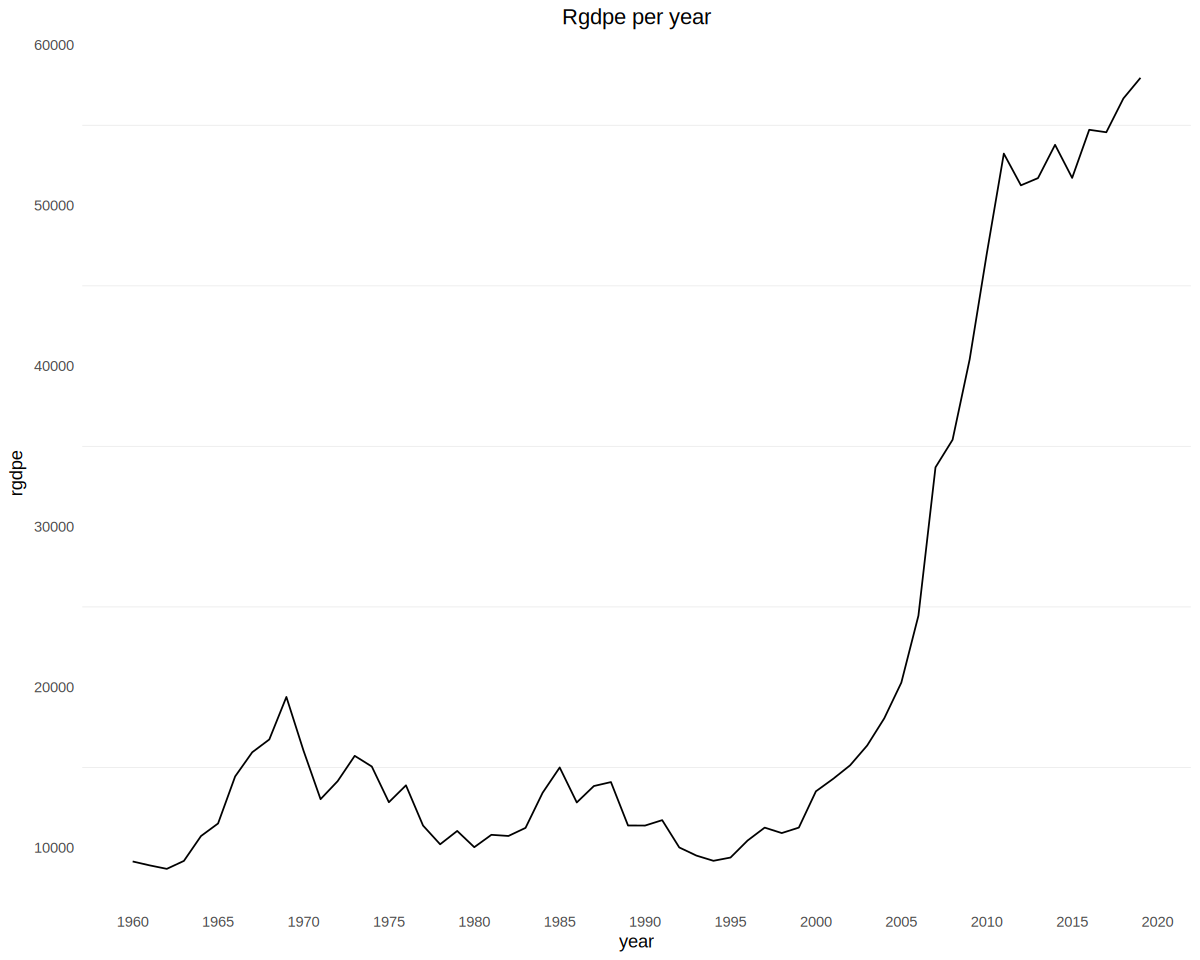

In [7]:
options(repr.plot.width=10,repr.plot.height=8)
ggplot(query,aes(x=year,y=rgdpe)) +
  geom_line() +
  theme_minimal() +
  labs(title="Rgdpe per year") +
  scale_x_continuous(breaks=seq(from=1960,to=2020,by=5)) +
  theme(panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank(),
        panel.grid.major.y=element_blank(),
        plot.title=element_text(hjust=0.5))

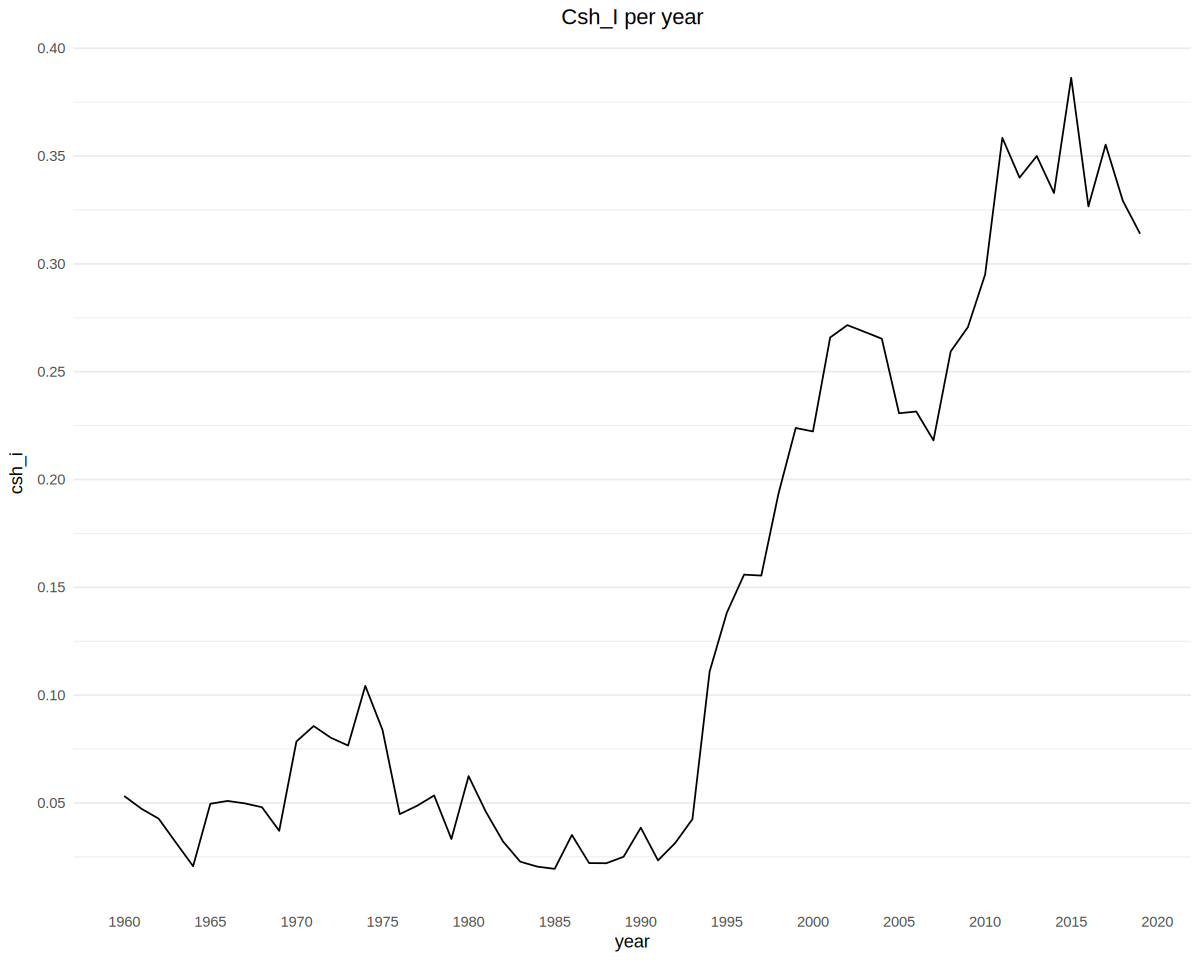

In [8]:
options(repr.plot.width=10,repr.plot.height=8)
ggplot(query,aes(x=year,y=csh_i)) +
  geom_line() +
  labs(title="Csh_I per year",x="year",y="csh_i") +
  theme_minimal() +
  scale_x_continuous(breaks=seq(from=1960,to=2020,by=5))+
  scale_y_continuous(breaks=seq(from=-0.1,to=0.4,by=0.05))+
  theme(plot.title=element_text(hjust=0.5),
        panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank())

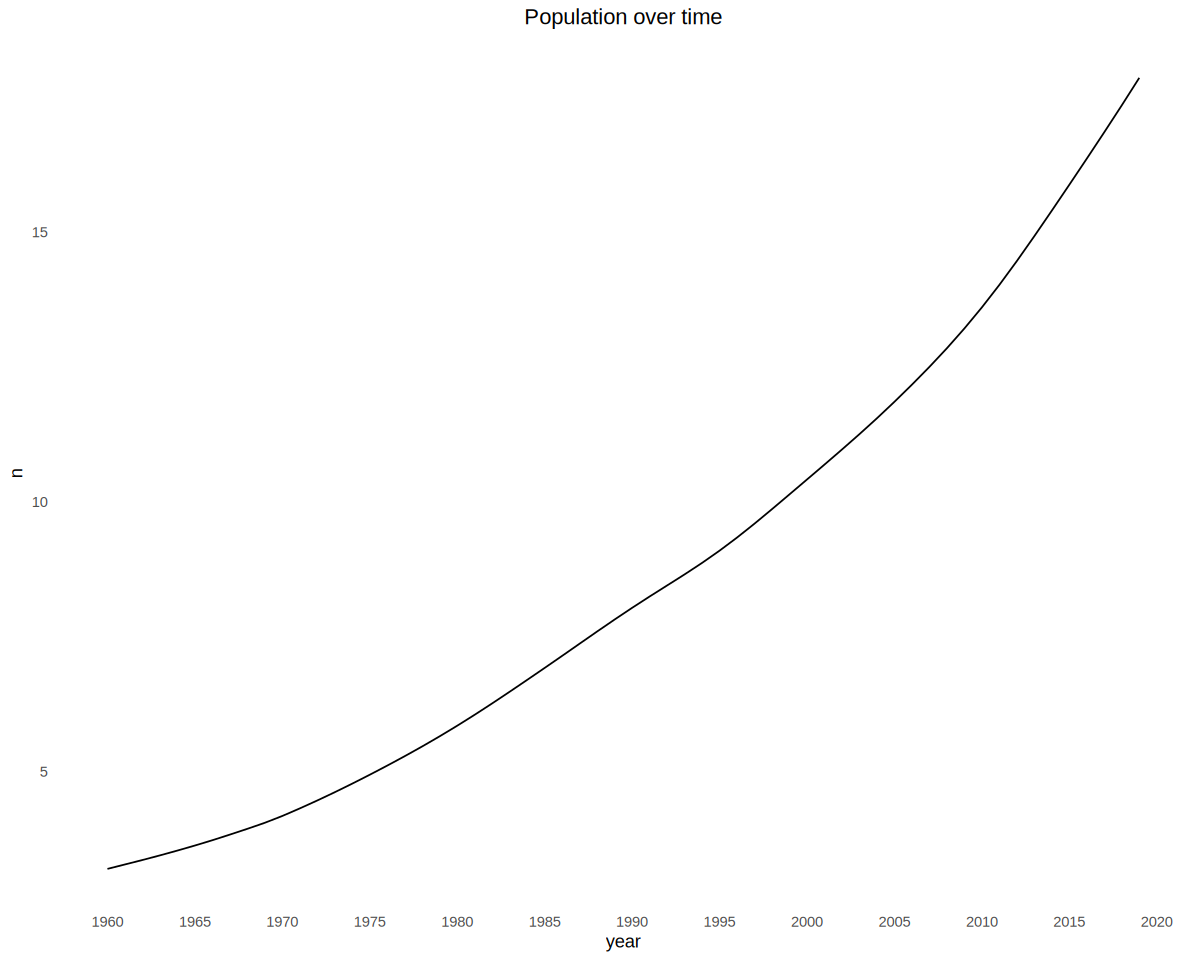

In [11]:
ggplot(query,aes(x=year,y=n)) +
  geom_line() +
  theme_minimal() +
  labs(title="Population over time") +
  scale_x_continuous(breaks=seq(from=1960,to=2020,by=5)) +
  theme(panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank(),
        panel.grid.major.y=element_blank(),
        panel.grid.minor.y=element_blank(),
        plot.title=element_text(hjust=0.5))

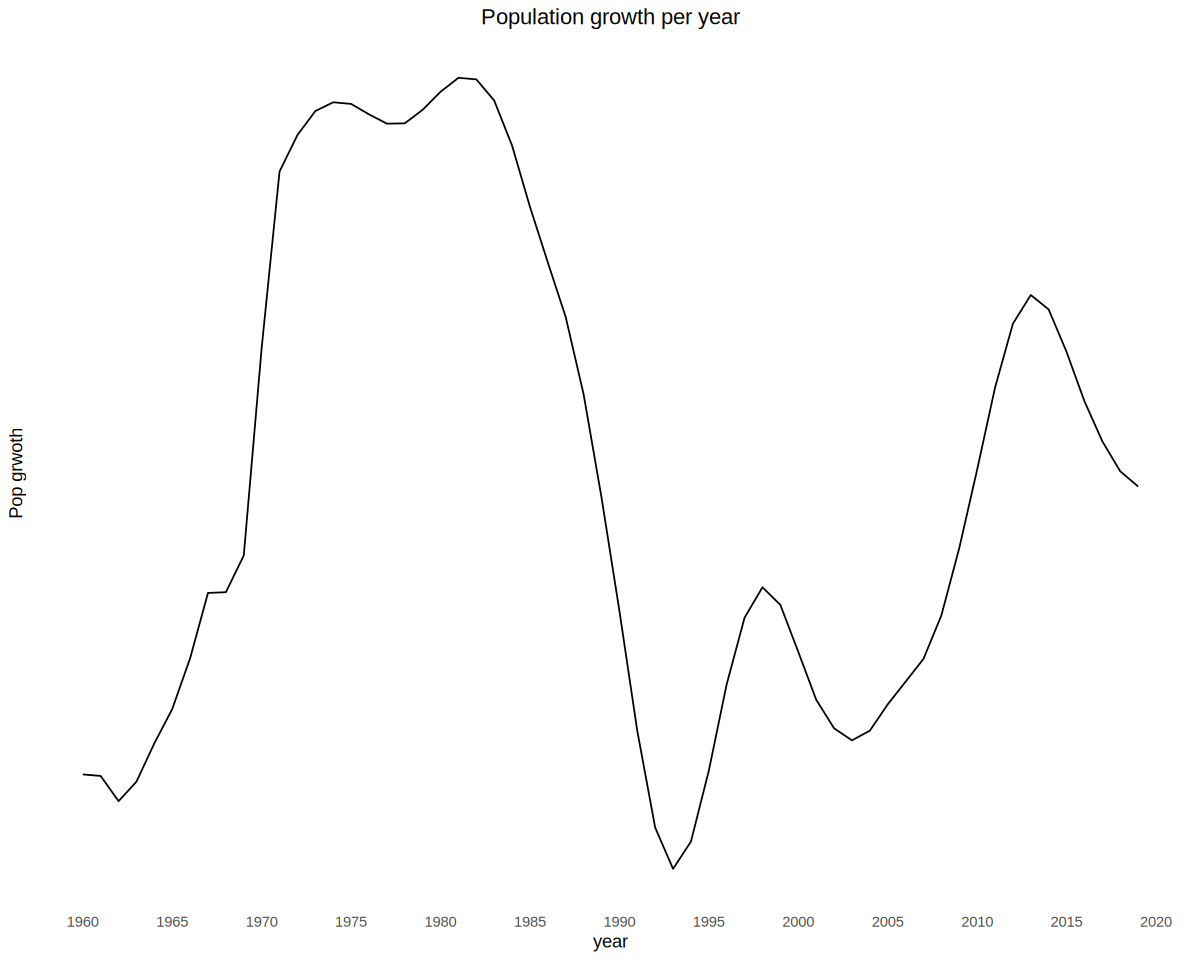

In [15]:
options(repr.plot.width=10,repr.plot.height=8)
ggplot(query,aes(x=year,y=pop_growth))+
  geom_line() +
  labs(title="Population growth per year",x="year",y="Pop grwoth") +
  theme_minimal() +
  scale_x_continuous(breaks=seq(from=1960,to=2020,by=5)) +
  scale_y_continuous(breaks=seq(from=0.8,to=3.2,by=0.4)) +
  theme(plot.title=element_text(hjust=0.5),
        panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank())

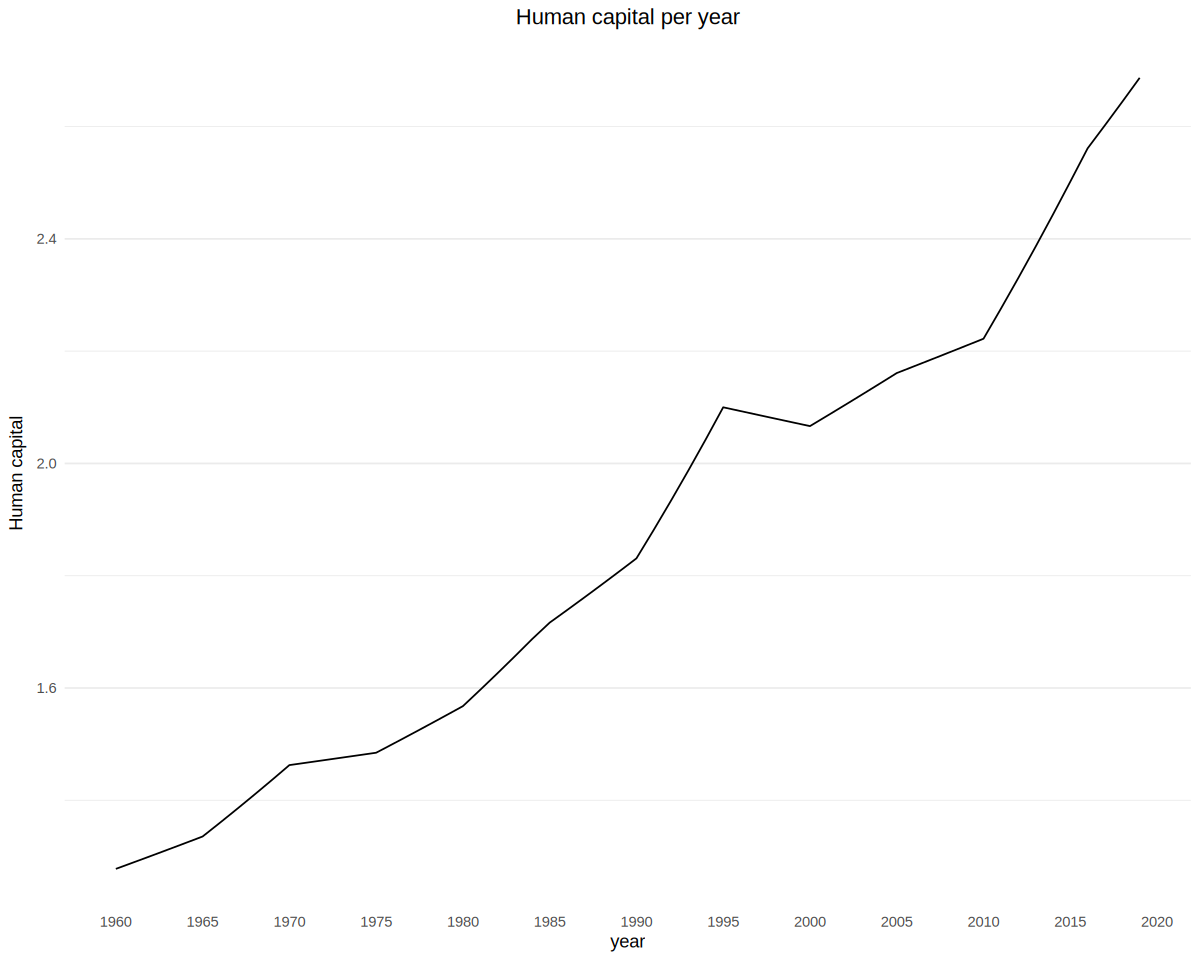

In [ ]:
options(repr.plot.width=10,repr.plot.height=8)
ggplot(query,aes(x=year,y=hc))+
  geom_line() +
  labs(title="Human capital per year",x="year",y="Human capital") +
  theme_minimal() +
  scale_x_continuous(breaks=seq(from=1960,to=2020,by=5)) +
  scale_y_continuous(breaks=seq(from=0.8,to=3.2,by=0.4)) +
  theme(plot.title=element_text(hjust=0.5),
        panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank())

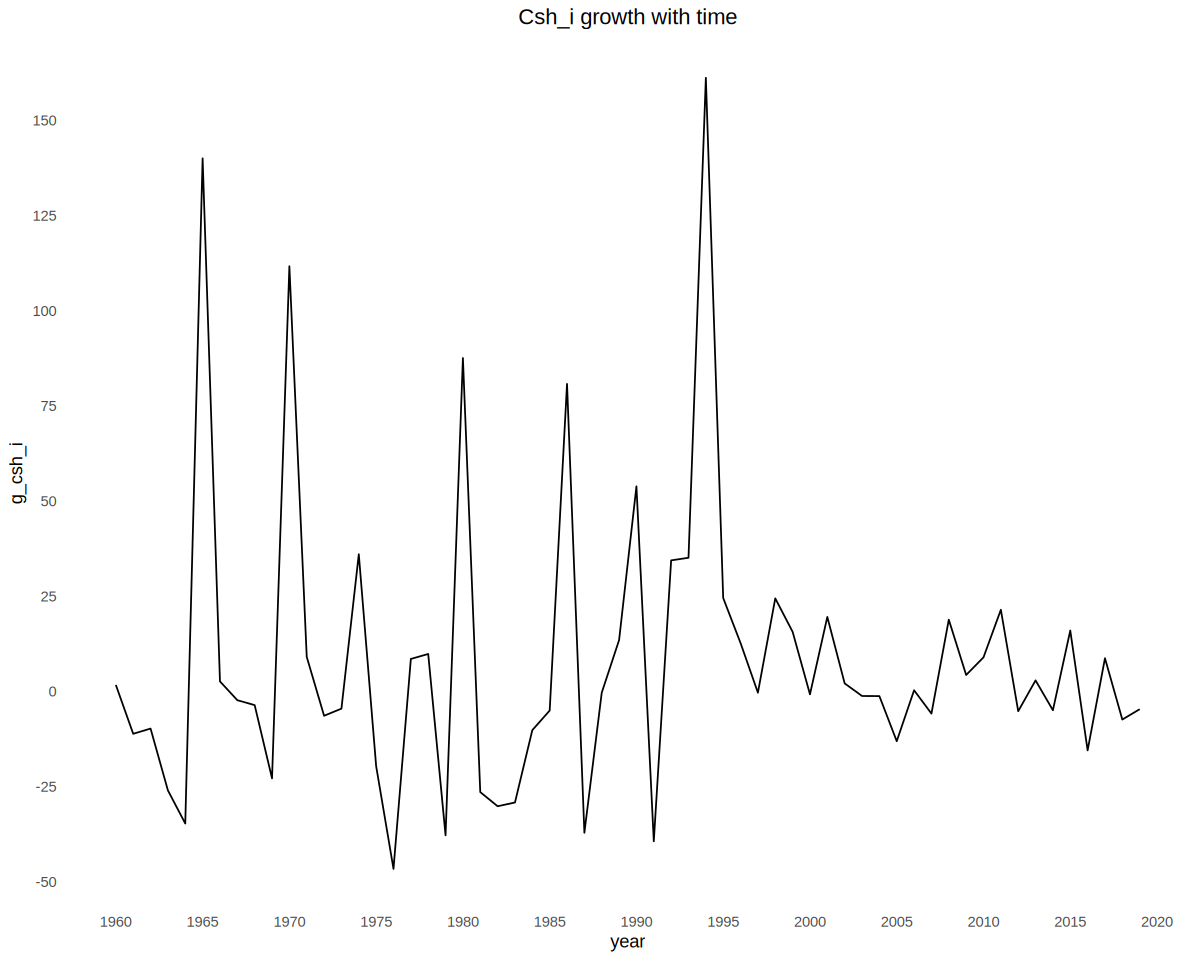

In [ ]:
gcshi <- query %>%
  select(year,g_csh_i) %>%
  mutate(g_csh_i = 100 * g_csh_i)
options(repr.plot.width=10,repr.plot.height=8)
ggplot(gcshi,aes(x=year,y=g_csh_i)) +
  geom_line() +
  labs(title="Csh_i growth with time",x="year",y="g_csh_i") +
  scale_x_continuous(breaks=seq(from=1960,to=2020,by=5)) +
  scale_y_continuous(breaks=seq(from=-50,to=155,by=25)) +
  theme_minimal() +
  theme(plot.title=element_text(hjust=0.5),
        panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank(),
        panel.grid.major.y=element_blank(),
        panel.grid.minor.y=element_blank())

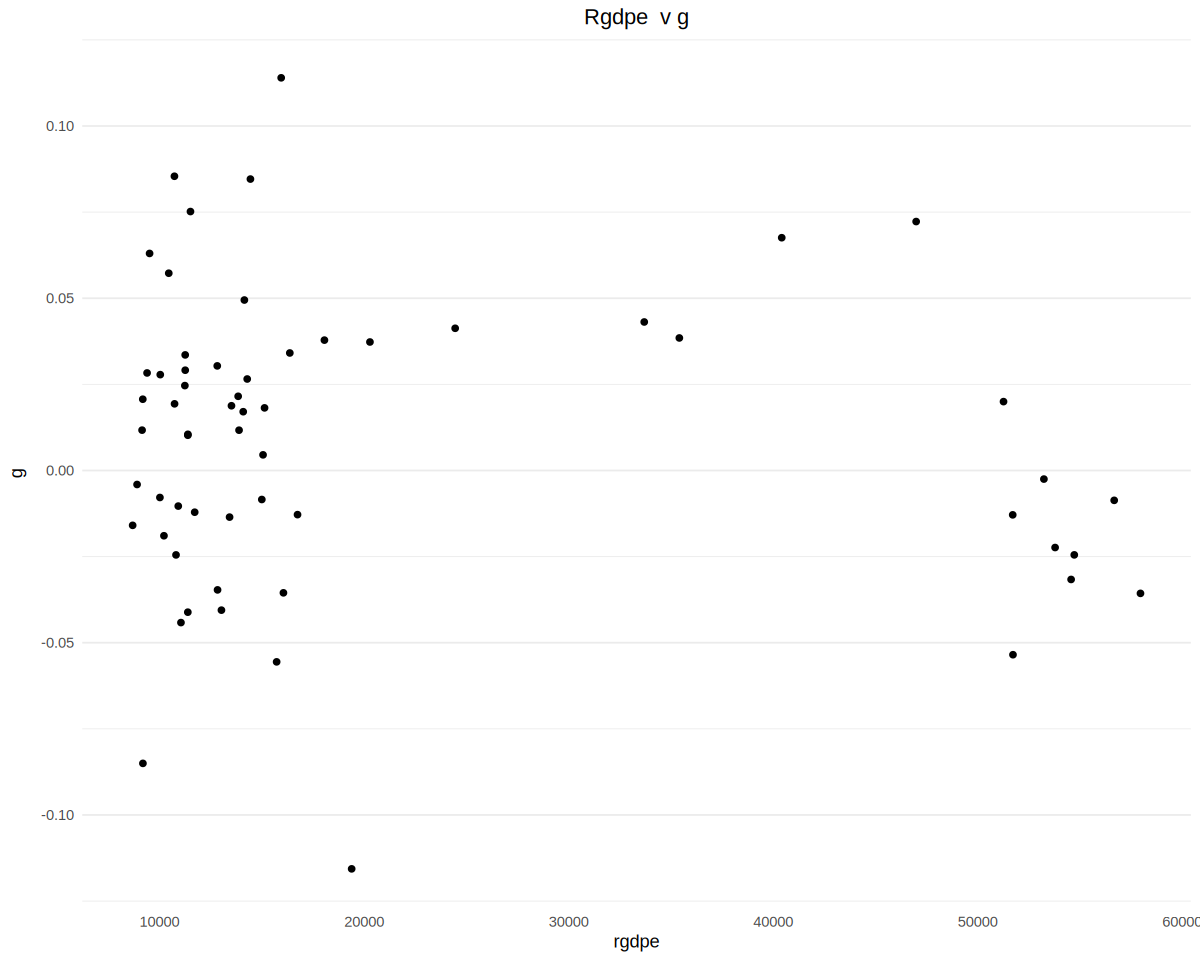

In [ ]:
ggplot(query,aes(x=rgdpe,y=g)) +
  geom_point() +
  labs(title="Rgdpe  v g",x="rgdpe",y="g") +
  theme_minimal()  +
  theme(plot.title=element_text(hjust=0.5),
        panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank())

In [ ]:
zams <- read_csv("zams.csv")
zams_new <- as.data.frame(t(zams))
zams_new <- zams_new[-c(1,2),]
print(head(zams_new))
colnames(zams_new)


New names:
• `` -> `...69`
Rows: 2 Columns: 69
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (38): Country Name, Country Code, Year, 1960, 1961, 1962, 1963, 1964, 19...
dbl (31): 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, ...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


                   V1                              V2
Year Trade (% of GDP) External debt stocks (% of GNI)
1960               ..                              ..
1961               ..                              ..
1962               ..                              ..
1963               ..                              ..
1964               ..                              ..


[1] "V1" "V2"

In [ ]:
zams_new <- zams_new %>% row_to_names(row_number = 1) %>%
                         rownames_to_column(var="year")
zams_new <- zams_new %>% rename(year = year,
                                trade_pgdp = `Trade (% of GDP)`,
                                gni_stocks = `External debt stocks (% of GNI)`) %>%
            mutate(trade_pgdp = as.numeric(trade_pgdp),
                   gni_stocks = as.numeric(gni_stocks),
                   year = as.numeric(year))
print(head(zams_new))
head(query)

Warning message:
“There were 3 warnings in `mutate()`.
The first warning was:
ℹ In argument: `trade_pgdp = as.numeric(trade_pgdp)`.
Caused by warning:
! NAs introduced by coercion
ℹ Run `dplyr::last_dplyr_warnings()` to see the 2 remaining warnings.”


  year trade_pgdp gni_stocks
1 1960         NA         NA
2 1961         NA         NA
3 1962         NA         NA
4 1963         NA         NA
5 1964         NA         NA
6 1965         NA         NA


,year,country,per_capita,y,rgdpe,csh_i,delta,hc,hc_grow,n,rtfpna,g,g_csh_i
,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1960,Zambia,2858.762,0.03607457,9143.686,0.05320368,0.03263622,1.277846,0.005782947,3.198477,0.6116154,0.011708910,0.01751087
2,1961,Zambia,2713.068,-0.05096428,8899.026,0.04730785,0.03180699,1.289174,0.008865186,3.280061,0.6091271,-0.004068431,-0.11081609
3,1962,Zambia,2582.095,-0.04827458,8682.625,0.04271275,0.03106741,1.300603,0.008865236,3.362628,0.5994263,-0.015925699,-0.09713196
4,1963,Zambia,2661.708,0.03083262,9177.950,0.03162815,0.03035675,1.312133,0.008865243,3.448143,0.6118268,0.020687293,-0.25951497
5,1964,Zambia,3031.894,0.13907818,10725.598,0.02066904,0.02986666,1.323765,0.008865201,3.537590,0.6640823,0.085408988,-0.34649852
6,1965,Zambia,3169.792,0.04548270,11509.419,0.04961916,0.03002951,1.335501,0.008865286,3.630969,0.7139981,0.075165062,1.40065126


In [ ]:
query <- query %>% inner_join(zams_new,by = "year")
query2 <- query %>% drop_na()
head(query)
cat("\n")
head(query2)
cat("\n")
dim(query2)

,year,country,per_capita,y,rgdpe,csh_i,delta,hc,hc_grow,n,rtfpna,g,g_csh_i,trade_pgdp,gni_stocks
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1960,Zambia,2858.762,0.03607457,9143.686,0.05320368,0.03263622,1.277846,0.005782947,3.198477,0.6116154,0.011708910,0.01751087,NA,NA
2,1961,Zambia,2713.068,-0.05096428,8899.026,0.04730785,0.03180699,1.289174,0.008865186,3.280061,0.6091271,-0.004068431,-0.11081609,NA,NA
3,1962,Zambia,2582.095,-0.04827458,8682.625,0.04271275,0.03106741,1.300603,0.008865236,3.362628,0.5994263,-0.015925699,-0.09713196,NA,NA
4,1963,Zambia,2661.708,0.03083262,9177.950,0.03162815,0.03035675,1.312133,0.008865243,3.448143,0.6118268,0.020687293,-0.25951497,NA,NA
5,1964,Zambia,3031.894,0.13907818,10725.598,0.02066904,0.02986666,1.323765,0.008865201,3.537590,0.6640823,0.085408988,-0.34649852,NA,NA
6,1965,Zambia,3169.792,0.04548270,11509.419,0.04961916,0.03002951,1.335501,0.008865286,3.630969,0.7139981,0.075165062,1.40065126,NA,NA


,year,country,per_capita,y,rgdpe,csh_i,delta,hc,hc_grow,n,rtfpna,g,g_csh_i,trade_pgdp,gni_stocks
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1994,Zambia,1035.477,-0.057500634,9184.408,0.1109860,0.03428556,2.043172,0.027805434,8.869740,0.6502615,-0.08502325,1.612278332,66.65059,199.0559
2,1995,Zambia,1032.006,-0.003352011,9387.750,0.1382662,0.03381743,2.099983,0.027805336,9.096607,0.6686716,0.02831191,0.245798584,69.22677,195.1709
3,1996,Zambia,1118.658,0.083965456,10447.972,0.1558887,0.03366626,2.093237,-0.003212659,9.339733,0.7069620,0.05726336,0.127453770,63.82148,208.1863
4,1997,Zambia,1172.333,0.047981316,11251.596,0.1554471,0.03376263,2.086512,-0.003212648,9.597609,0.7306803,0.03354961,-0.002832764,58.27286,164.3397
5,1998,Zambia,1106.011,-0.056573024,10912.429,0.1935060,0.03416923,2.079809,-0.003212719,9.866476,0.7231281,-0.01033586,0.244834776,56.25031,207.2503
6,1999,Zambia,1109.700,0.003335613,11252.980,0.2239003,0.03500267,2.073127,-0.003212642,10.140561,0.7441766,0.02910763,0.157071861,59.76753,183.7147


[1] 26 15

 Correlation Matrix

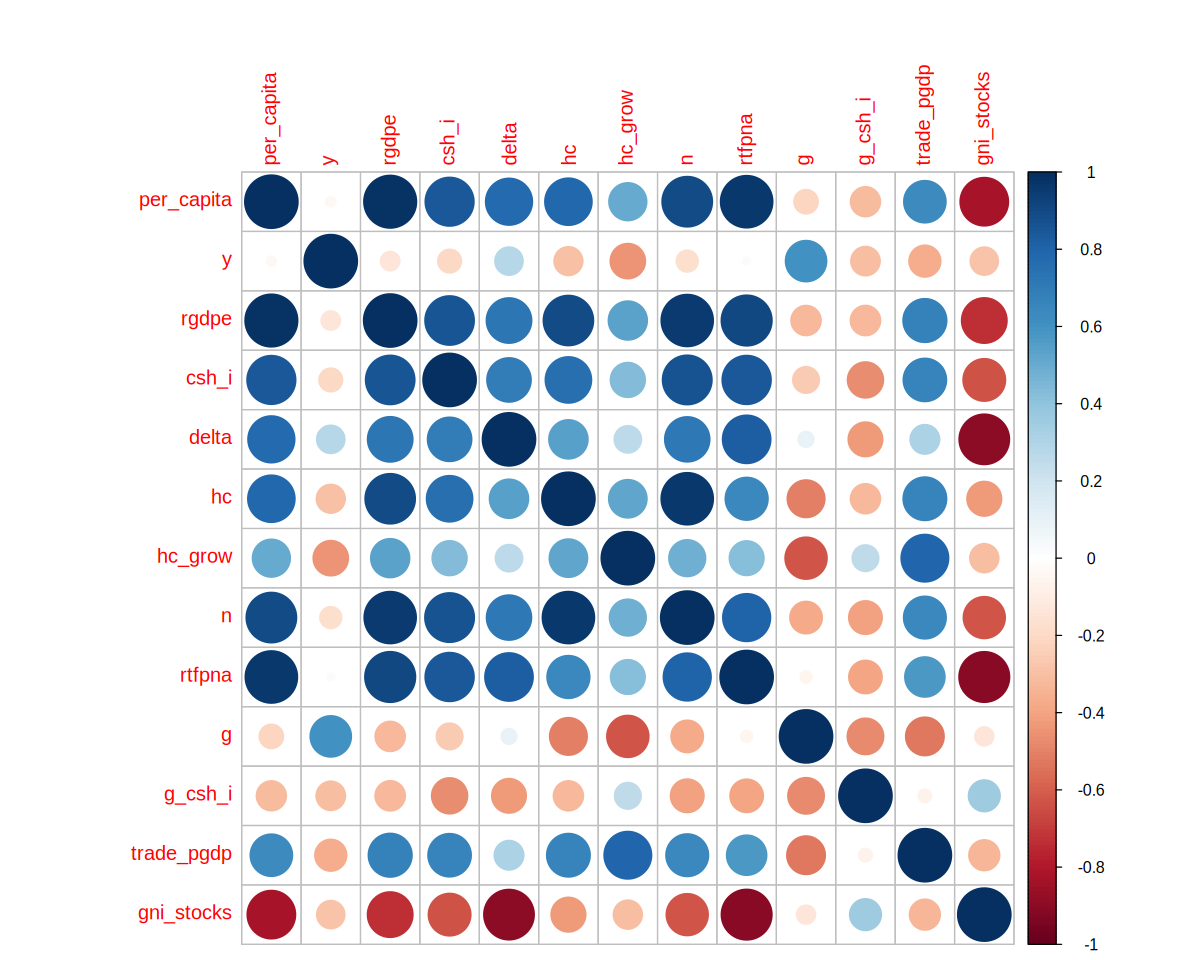

In [ ]:
options(repr.plot.width=10,repr.plot.height=8)
cat("====================\n")
cat(" Correlation Matrix\n")
cat("=====================")
query3 <- query %>% select(-country,-year)
corr <- cor(query3,use="complete.obs")
corrplot(corr,method="circle")


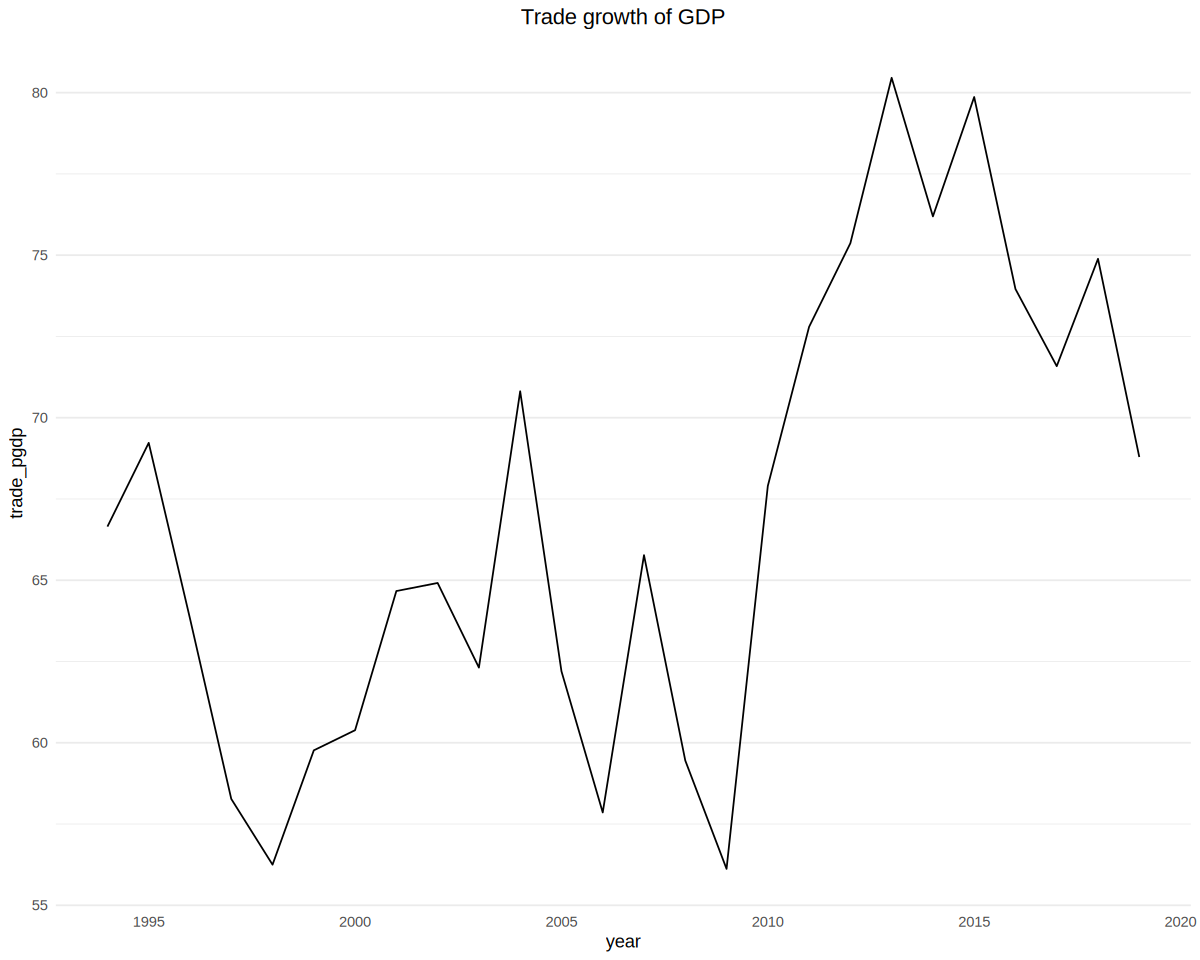

In [ ]:
options(repr.plot.width=10,repr.plot.height=8)
ggplot(query2,aes(x=year)) +
  geom_line(aes(y=trade_pgdp)) +
  scale_x_continuous(breaks=seq(from=1995,to=2020,by=5))+
  theme_minimal()+
  labs(title="Trade growth of GDP") +
  theme(panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank(),
        plot.title=element_text(hjust=0.5))

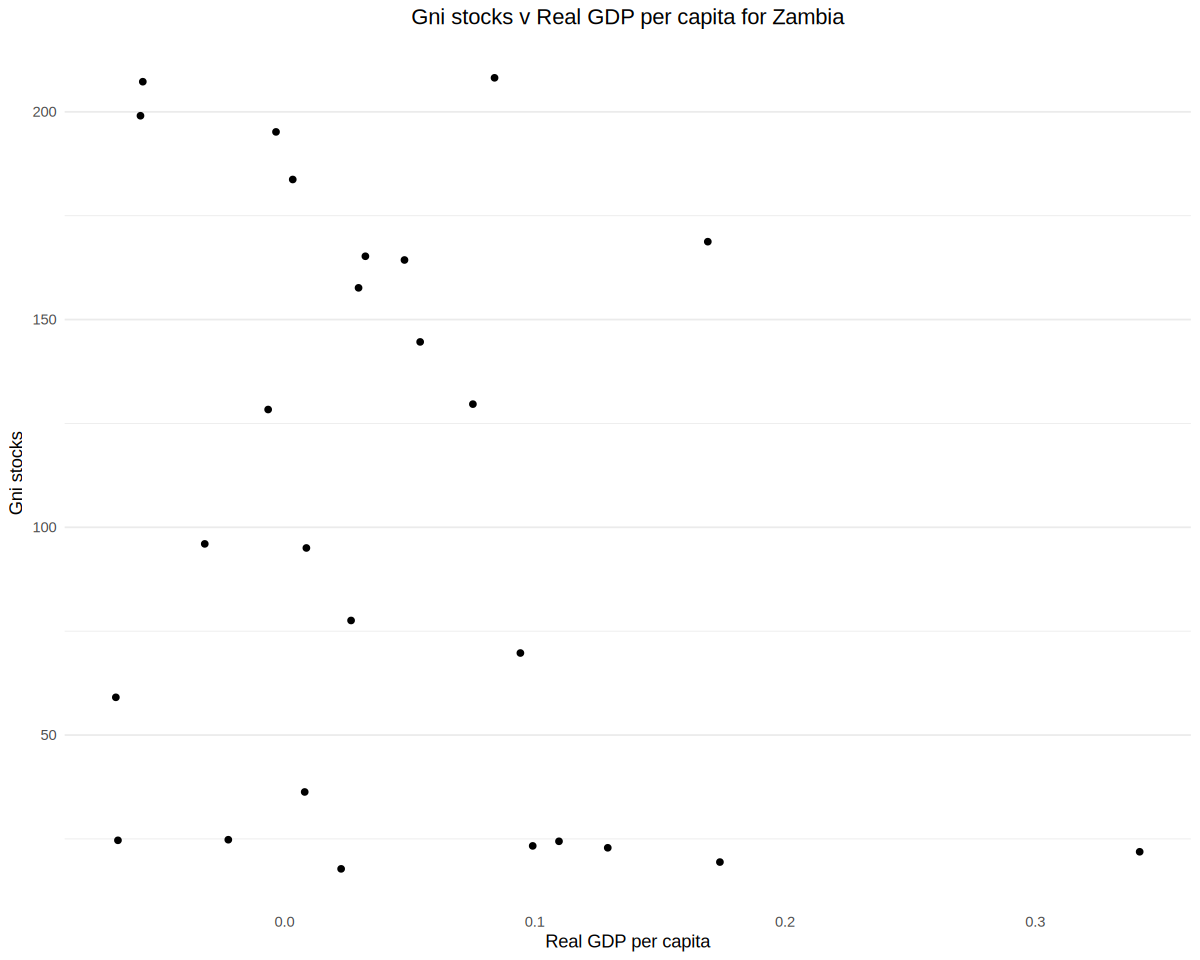

In [ ]:
ggplot(query2,aes(x=y)) +
  geom_point(aes(y=gni_stocks)) +
  theme_minimal() +
  labs(title="Gni stocks v Real GDP per capita for Zambia",x="Real GDP per capita",y= "Gni stocks")+
  theme(panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank(),
        plot.title=element_text(hjust=0.5))

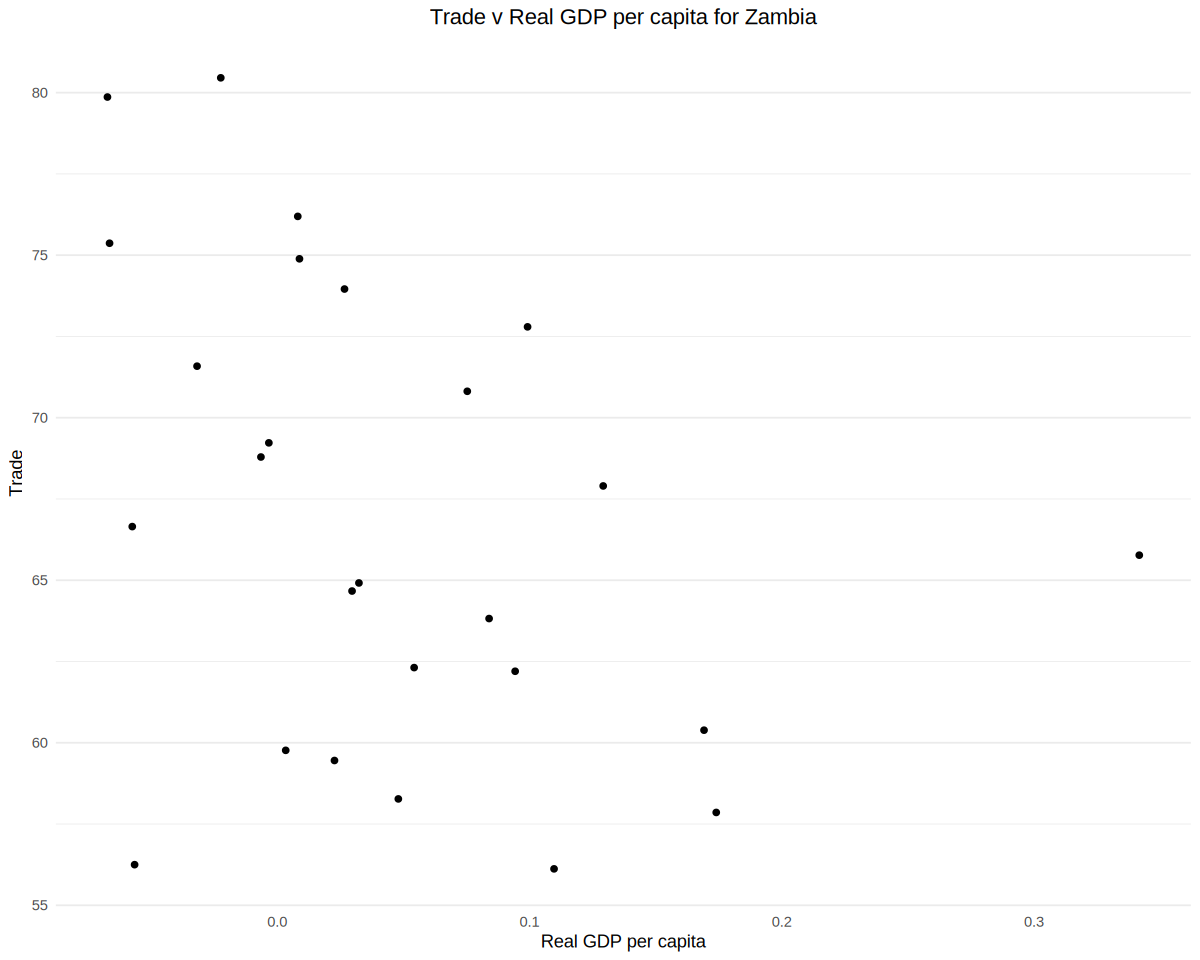

In [ ]:
ggplot(query2,aes(x=y)) +
  geom_point(aes(y=trade_pgdp)) +
  theme_minimal() +
  labs(title="Trade v Real GDP per capita for Zambia",x="Real GDP per capita",y= "Trade")+
  theme(panel.grid.major.x=element_blank(),
        panel.grid.minor.x=element_blank(),
        plot.title=element_text(hjust=0.5))